# Linear Regression: House Price Prediction
Steps: Load, EDA, Fill missing, Split, Train, Evaluate

## 1. Import and load data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

df = pd.read_csv('house_prices.csv')
df.head()

,area_sqft,bedrooms,age_years,distance_km,price_lakh
0,1626.0,1,26.0,13.6,65.76
1,1959.0,2,25.0,18.0,87.81
2,1360.0,2,8.0,3.6,83.96
3,1794.0,4,12.0,14.6,100.18
4,1630.0,2,25.0,7.2,68.72


## 2. Simple EDA

In [2]:
print(df.shape)
print(df.isnull().sum())
df.describe()

(1000, 5)
area_sqft      50
bedrooms        0
age_years      50
distance_km    50
price_lakh      0
dtype: int64


,area_sqft,bedrooms,age_years,distance_km,price_lakh
count,950.000000,1000.000000,950.000000,950.000000,1000.000000
mean,1536.817895,2.425000,14.449474,13.087579,73.800900
std,552.782592,1.095251,8.696079,6.894395,31.615444
min,501.000000,1.000000,0.000000,1.000000,-6.530000
25%,1101.000000,1.000000,7.000000,7.200000,50.925000
50%,1549.500000,2.000000,14.000000,13.300000,75.590000
75%,1997.750000,3.000000,22.000000,19.075000,97.495000
max,2498.000000,4.000000,29.000000,25.000000,155.920000


In [3]:
df.corr()['price_lakh'].sort_values()

age_years     -0.256692
distance_km   -0.243223
bedrooms       0.234529
area_sqft      0.886148
price_lakh     1.000000
Name: price_lakh, dtype: float64

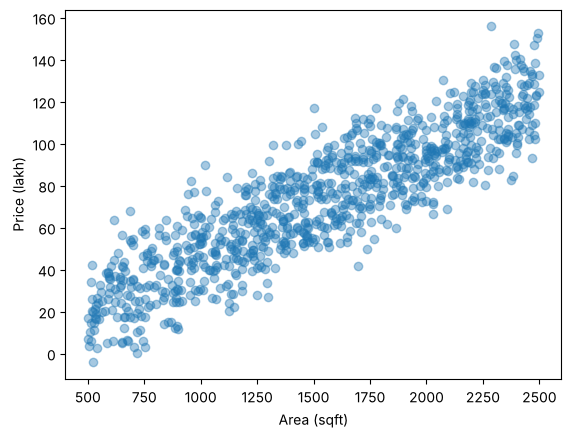

In [4]:
plt.scatter(df['area_sqft'], df['price_lakh'], alpha=0.4)
plt.xlabel('Area (sqft)')
plt.ylabel('Price (lakh)')
plt.show()

## 3. Fill missing values (median)

In [5]:
df = df.fillna(df.median())
df.isnull().sum()

area_sqft      0
bedrooms       0
age_years      0
distance_km    0
price_lakh     0
dtype: int64

## 4. Train test split

In [6]:
X = df.drop('price_lakh', axis=1)
y = df['price_lakh']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(800, 4) (200, 4)


## 5. Train the model

In [7]:
model = LinearRegression()
model.fit(X_train, y_train)

print('Intercept:', model.intercept_)
pd.Series(model.coef_, index=X.columns)

Intercept: 9.292128489342687


area_sqft      0.049599
bedrooms       6.108364
age_years     -0.778591
distance_km   -1.165908
dtype: float64

## 6. Evaluate

In [8]:
y_pred = model.predict(X_test)

print('R2 score:', r2_score(y_test, y_pred))
print('MAE:', mean_absolute_error(y_test, y_pred))

R2 score: 0.8612568990534839
MAE: 7.425848946094693


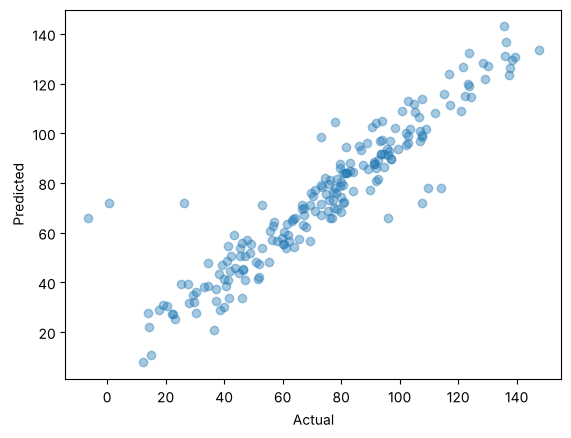

In [9]:
plt.scatter(y_test, y_pred, alpha=0.4)
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.show()

## 7. Predict on a new house

In [10]:
new_house = pd.DataFrame([[1200, 2, 5, 8]], columns=X.columns)
print('Predicted price (lakh):', model.predict(new_house)[0])

Predicted price (lakh): 67.80796721990089
